<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<hr style="height:.9px;border:none;color:#333;background-color:#333;" />

<h1>Script 05 | Nonparametric Modeling with Regression Trees</h1>
DAT-7470 - Business Analysis with Structured Data<br>
Script 05 - Completed Notebook<br><br>
Based on the course script by Chase Kusterer, Hult International Business School<br>
<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<hr style="height:.9px;border:none;color:#333;background-color:#333;" />

<h2>Part I: Preparation and Exploration</h2>
<h4>a) Imports and Initial Setup</h4>
This script uses <code>diamonds_prepped.xlsx</code>, the file saved at the end of Script 04 (channel one-hot encoded, independent dropped, store removed).<br><br>
<strong>Google Colab:</strong> upload <strong>either</strong> <code>diamonds_prepped.xlsx</code> <strong>or</strong> the original <code>diamonds.xlsx</code> with the folder icon on the left (Files &rarr; Upload). If only <code>diamonds.xlsx</code> is found, the cell below repeats the Script 04 preparation steps automatically. If neither file is found, an upload button appears.

In [1]:
# importing libraries
import matplotlib.pyplot as plt                      # data visualization
import numpy as np                                   # mathematical essentials
import pandas as pd                                  # data science essentials
from sklearn.model_selection import train_test_split # train-test split
from sklearn.tree import DecisionTreeRegressor       # regression trees
from sklearn.tree import plot_tree                   # tree plots
from sklearn.tree import export_text                 # tree rules as text
import os                                            # files and folders
import warnings                                      # warnings from code

warnings.filterwarnings("ignore")


# new libraries
from sklearn.preprocessing import StandardScaler  # standard scaler


########################################
# finding the dataset (Colab or local)
########################################
def find_file(name):
    """Returns the path of a file in the usual places, or None."""
    for folder in ['.', './datasets', '/content', '/content/datasets']:
        path = os.path.join(folder, name)
        if os.path.exists(path):
            return path
    return None


def prepare_diamonds(raw_file):
    """Repeats the Script 04 preparation steps on the original diamonds.xlsx."""
    data = pd.read_excel(io      = raw_file,
                         dtype   = {"channel" : str, "store" : str},
                         usecols = range(1, 8))                       # omitting Obs

    one_hot_channel = pd.get_dummies(data   = data['channel'],
                                     prefix = 'channel',
                                     dtype  = int)

    data = data.join([one_hot_channel])
    data = data.rename(columns = {'channel_0': 'mall',
                                  'channel_1': 'independent',
                                  'channel_2': 'internet'})

    return data.drop(['independent', 'channel', 'store'], axis = 1)


prepped_file = find_file('diamonds_prepped.xlsx')
raw_file     = find_file('diamonds.xlsx')

if prepped_file is None and raw_file is None:          # nothing found -> upload button
    from google.colab import files
    uploaded = files.upload()                          # choose either Excel file
    name     = list(uploaded.keys())[0]
    if 'prepped' in name:
        prepped_file = name
    else:
        raw_file = name


# reading the file into Python
if prepped_file is not None:
    file     = prepped_file
    diamonds = pd.read_excel(io     = file,
                             header = 0)
else:
    file     = raw_file
    diamonds = prepare_diamonds(raw_file)

print("Data loaded from:", file)


# checking the dataset
diamonds.head(n = 5)

Data loaded from: ./datasets/diamonds_prepped.xlsx


,carat,color,clarity,cut,price,mall,internet
0,0.32,3,7,0,1375,1,0
1,0.35,5,7,1,1680,1,0
2,0.40,4,7,1,2245,1,0
3,0.59,5,7,0,2495,1,0
4,0.72,7,8,0,2699,1,0


In [2]:
## x-side ##
x_all  = diamonds.drop(labels = 'price', axis = 1)
x_base = diamonds[ ['carat', 'color', 'clarity', 'cut'] ]

## y-side ##
y_original = diamonds['price']

<h3>Which set of x-data should we use?</h3>
With OLS we chose features by their significance. Do regression trees need that, or is it better to give them all available x-data so they can choose for themselves? Let's find out! We start with all features.

In [3]:
# x-data
x_data = x_all

# y_data
y_data = y_original

In [4]:
# train-test split
x_train, x_test, y_train, y_test = train_test_split(x_data,
                                                    y_data,
                                                    test_size = 0.35,
                                                    random_state = 702)

In [5]:
# checking results
print(f"""
Data Shapes
-----------
x_train: {x_train.shape}
y_train: {y_train.shape}

x_test:  {x_test.shape}
y_test:  {y_test.shape}
""")


Data Shapes
-----------
x_train: (265, 6)
y_train: (265,)

x_test:  (144, 6)
y_test:  (144,)



<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part II: Regression Trees</h2>
CART models output useful tools such as <strong>tree plots</strong> and <strong>feature importance</strong>. They are nonparametric, so they have <strong>no coefficients</strong> and <strong>assume no model form</strong>: in theory, features do not need to be transformed or engineered.

<strong>Key Attributes</strong>

* tend to overfit unless pruned
* tend to be worse at prediction than other model types (after pruning)
* can generate very useful outputs for developing hypotheses and data-driven findings

Run the following code to load a user-defined function for CART model output.

In [6]:
########################################
# plot_feature_importances
########################################
def plot_feature_importances(model, train, export = False):
    """
    Plots the importance of features from a CART model.

    PARAMETERS
    ----------
    model  : CART model
    train  : training data (x-side)
    export : whether or not to export as a .png image, default False
    """

    # declaring the number of features (from the data passed in)
    n_features = train.shape[1]

    # setting plot window
    fig, ax = plt.subplots(figsize=(10, 8))

    plt.barh(range(n_features), model.feature_importances_, align='center')
    plt.yticks(np.arange(n_features), train.columns)
    plt.xlabel("Feature importance")
    plt.ylabel("Feature")

    if export == True:
        os.makedirs('./analysis_images', exist_ok = True)
        plt.savefig('./analysis_images/Tree Visual.png')

    plt.show()

<em>Small fix to the class function:</em> it counted features with the global <code>x_train</code> instead of the <code>train</code> argument. This breaks when the function is called on a different feature set, so it now uses <code>train.shape[1]</code>. It also creates the <code>analysis_images</code> folder before saving.

In [7]:
########################################
# run_tree: the model building framework for regression trees
########################################
def run_tree(x_data, y_data, max_depth = None, min_samples_leaf = 1, name = "Regression Tree"):
    """
    Splits the data, fits a regression tree on the training set and
    prints the training score, testing score and train-test gap.
    Returns the fitted model and the training x-data.
    """

    # train-test split (same settings as the rest of the course)
    x_train, x_test, y_train, y_test = train_test_split(x_data,
                                                        y_data,
                                                        test_size    = 0.35,
                                                        random_state = 702)

    # INSTANTIATING, FITTING, PREDICTING
    model      = DecisionTreeRegressor(max_depth        = max_depth,
                                       min_samples_leaf = min_samples_leaf,
                                       random_state     = 702)
    model_fit  = model.fit(x_train, y_train)
    model_pred = model.predict(x_test)

    # SCORING the results (R-square)
    train_score = model.score(x_train, y_train)
    test_score  = model.score(x_test,  y_test)
    gap         = abs(train_score - test_score)

    print(name)
    print('Training Score :', round(train_score, ndigits = 4))
    print('Testing Score  :', round(test_score,  ndigits = 4))
    print('Train-Test Gap :', round(gap,         ndigits = 4))

    return model, x_train

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
Run the following code to develop a regression tree. It overfits to the training data, because it was allowed to keep growing until it could not grow any further.

In [8]:
model_name = 'Unpruned Regression Tree'

# INSTANTIATING a model object
model = DecisionTreeRegressor(random_state = 702)


# FITTING to the training data
model_fit = model.fit(x_train, y_train)


# PREDICTING on new data
model_pred = model.predict(x_test)


# SCORING the results (R-square)
model_train_score = model.score(x_train, y_train)
model_test_score  = model.score(x_test, y_test)
model_gap         = abs(model_train_score - model_test_score)


# displaying results
print('Training Score :', round(model_train_score, ndigits = 4))
print('Testing Score  :', round(model_test_score, ndigits = 4))
print('Train-Test Gap :', round(model_gap, ndigits = 4))
print('Tree depth     :', model.get_depth())
print('Terminal nodes :', model.get_n_leaves())

Training Score : 0.9995
Testing Score  : 0.9324
Train-Test Gap : 0.0671
Tree depth     : 15
Terminal nodes : 219


<strong>Why is this overfit?</strong> The training score is almost perfect (0.9995). The tree grew until nearly every training diamond sat in its own terminal node (more than 200 leaves), so it has memorized the training prices. The gap (0.067) is above the 0.05 rule of thumb.

Notice that the testing score (0.93) is still high. This dataset has one feature, carat, that explains most of the price, so even a memorizing tree predicts reasonably well. But a model this large cannot be interpreted or explained, and its results would not be stable on another sample of diamonds.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h4>a) Develop a new regression tree.</h4>
Develop a regression tree with a maximum depth of 4 and a minimum number of samples per leaf of 25.

In [9]:
help(DecisionTreeRegressor)

Help on class DecisionTreeRegressor in module sklearn.tree._classes:

class DecisionTreeRegressor(sklearn.base.RegressorMixin, BaseDecisionTree)
 |  DecisionTreeRegressor(
 |      *,
 |      criterion='squared_error',
 |      splitter='best',
 |      max_depth=None,
 |      min_samples_split=2,
 |      min_samples_leaf=1,
 |      min_weight_fraction_leaf=0.0,
 |      max_features=None,
 |      random_state=None,
 |      max_leaf_nodes=None,
 |      min_impurity_decrease=0.0,
 |      ccp_alpha=0.0,
 |      monotonic_cst=None
 |  )
 |
 |  A decision tree regressor.
 |
 |  Read more in the :ref:`User Guide <tree>`.
 |
 |  Parameters
 |  ----------
 |  criterion : {"squared_error", "absolute_error", "poisson"}, default="squared_error"
 |      The function to measure the quality of a split. Supported criteria
 |      are "squared_error" for the mean squared error, which is equal to
 |      variance reduction as feature selection criterion and minimizes the L2
 |      loss using the mean of 

In [10]:
# naming the model
model_name = 'Pruned Regression Tree'

# INSTANTIATING a model object
model = DecisionTreeRegressor(max_depth        = 4,
                              min_samples_leaf = 25,
                              random_state     = 702)


# FITTING to the training data
model_fit = model.fit(x_train, y_train)


# PREDICTING on new data
model_pred = model.predict(x_test)


# SCORING the results
model_train_score = model.score(x_train, y_train) # using R-square
model_test_score  = model.score(x_test, y_test)   # using R-square
model_gap         = abs(model_train_score - model_test_score)


# displaying results
print('Training Score :', round(model_train_score, ndigits = 4))
print('Testing Score  :', round(model_test_score, ndigits = 4))
print('Train-Test Gap :', round(model_gap, ndigits = 4))

Training Score : 0.7592
Testing Score  : 0.7123
Train-Test Gap : 0.0468


<strong>Result:</strong> train 0.7592, test 0.7123, gap 0.047. Pruning has closed the gap to below 0.05, so the tree is no longer overfit. But accuracy dropped a lot, because a leaf must now contain at least 25 diamonds.

<em>Note:</em> the class sample solution uses <code>min_samples_leaf = 10</code>. The next cell compares the two settings.

In [11]:
# comparing with min_samples_leaf = 10 (as in the class sample solution)
tree_10, _ = run_tree(x_all, y_original,
                      max_depth = 4, min_samples_leaf = 10,
                      name = 'Pruned Tree (depth 4, leaf 10)')

Pruned Tree (depth 4, leaf 10)
Training Score : 0.8937
Testing Score  : 0.8459
Train-Test Gap : 0.0478


With 10 diamonds per leaf the tree is much more accurate (test 0.846) and still not overfit (gap 0.048). A minimum of 25 is too strict for a training set of only 265 diamonds: it leaves room for only about 10 leaves.

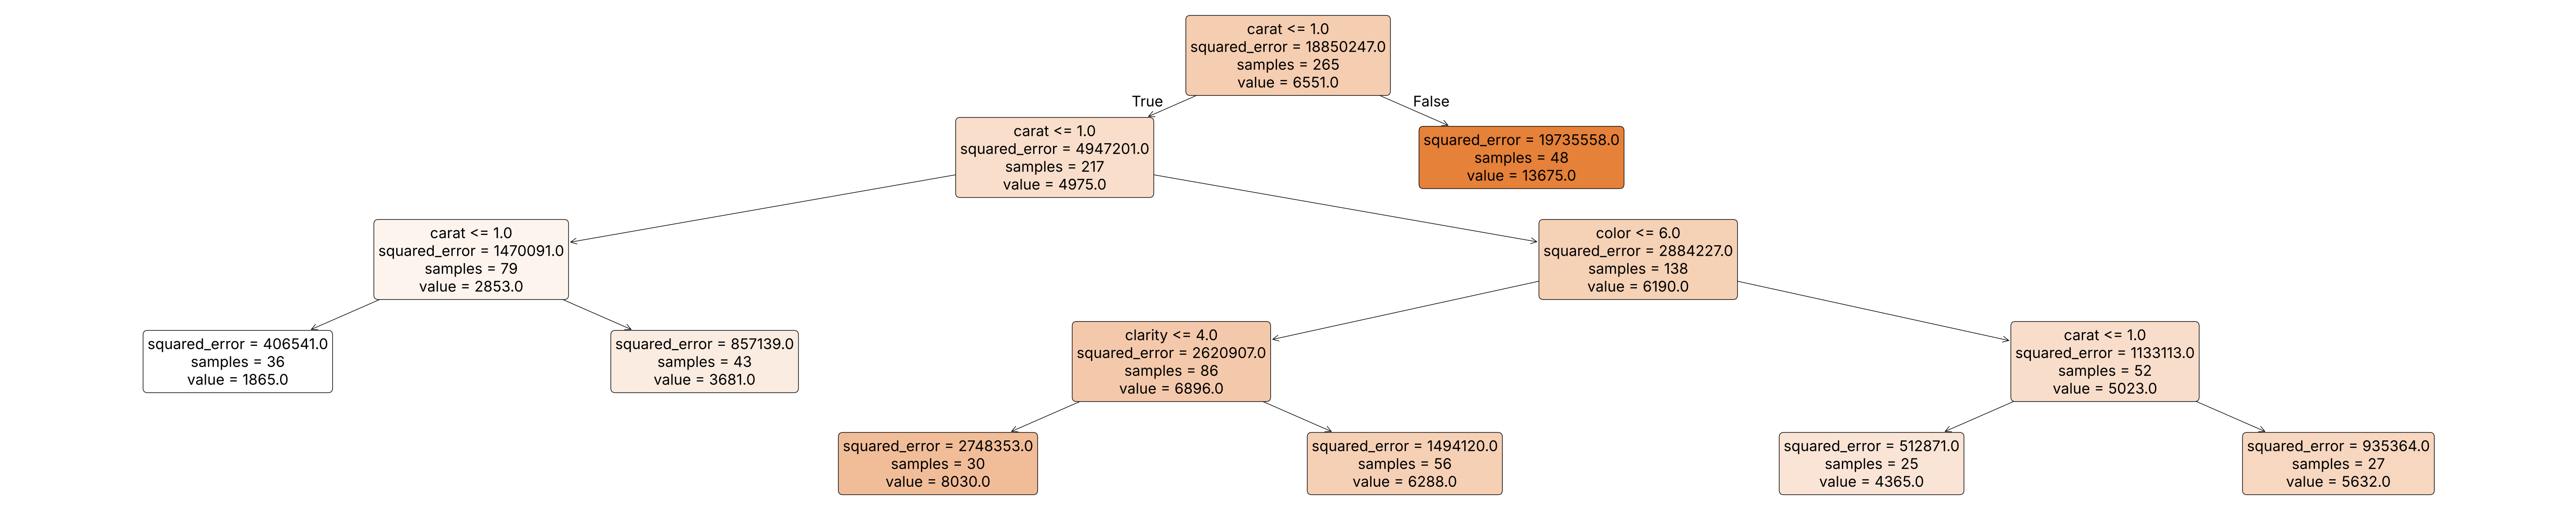

In [12]:
# setting figure size
plt.figure(figsize=(75, 15))


# developing a plotted tree
plot_tree(decision_tree = model,
          feature_names = list(x_train.columns),
          filled        = True,
          rounded       = True,
          fontsize      = 24,
          precision     = 0)


# saving the visual as .png file
os.makedirs('./analysis_images', exist_ok = True)
plt.savefig("./analysis_images/pruned tree.png")

# rendering the plot
plt.show()

In [13]:
# the same tree as text rules (easier to read than the plot)
print(export_text(model, feature_names = list(x_train.columns), decimals = 2))

|--- carat <= 1.44
|   |--- carat <= 0.88
|   |   |--- carat <= 0.66
|   |   |   |--- value: [1864.83]
|   |   |--- carat >  0.66
|   |   |   |--- value: [3681.16]
|   |--- carat >  0.88
|   |   |--- color <= 5.50
|   |   |   |--- clarity <= 4.50
|   |   |   |   |--- value: [8030.40]
|   |   |   |--- clarity >  4.50
|   |   |   |   |--- value: [6288.45]
|   |   |--- color >  5.50
|   |   |   |--- carat <= 1.02
|   |   |   |   |--- value: [4364.96]
|   |   |   |--- carat >  1.02
|   |   |   |   |--- value: [5632.19]
|--- carat >  1.44
|   |--- value: [13674.65]



<strong>Reading the tree:</strong>

* The first and most important split is **carat ≤ 1.44**. Every diamond above 1.44 carats goes to a single leaf with an average price of about **\$13,675**.
* Smaller diamonds are split by carat again (0.66 and 0.88), and only then by **color** (≤ 5.5) and **clarity** (≤ 4.5).
* **Cut, mall and internet are never used.** With 25 diamonds per leaf, they never give a better split than carat, color or clarity.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
CART models have an excellent tool for evaluating features. <strong>Feature importance</strong> shows how much each feature contributes to splitting the data into nodes (all importances add up to 1).

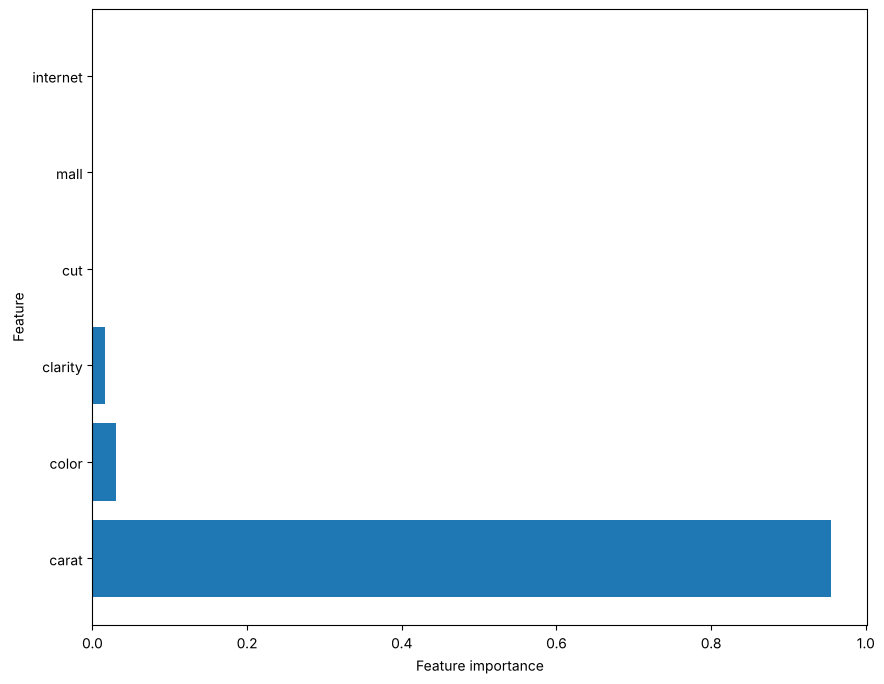

In [14]:
# plotting feature importance
plot_feature_importances(model,
                         train = x_train,
                         export = False)

In [15]:
# feature importance as a table
pd.Series(model.feature_importances_, index = x_train.columns)\
  .sort_values(ascending = False).round(3)

carat       0.954
color       0.030
clarity     0.016
cut         0.000
mall        0.000
internet    0.000
dtype: float64

**Carat** has an importance of **0.954**: it does almost all of the work. Color (0.030) and clarity (0.016) add a little, and cut and the channels contribute **0**. This matches what we found with correlation (Script 03) and OLS (Script 04): carat drives price.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part III: Further Analysis</h2>
Instead of changing and re-running the cells above, each task below calls <code>run_tree()</code> with the same pruning settings (depth 4, leaf 25) and the same train-test split, so all results can be compared fairly.

<strong>a) Develop a regression tree using only the base features.</strong><br>
How did the model perform? What new insights have you discovered?

Base Features Tree
Training Score : 0.7592
Testing Score  : 0.7123
Train-Test Gap : 0.0468


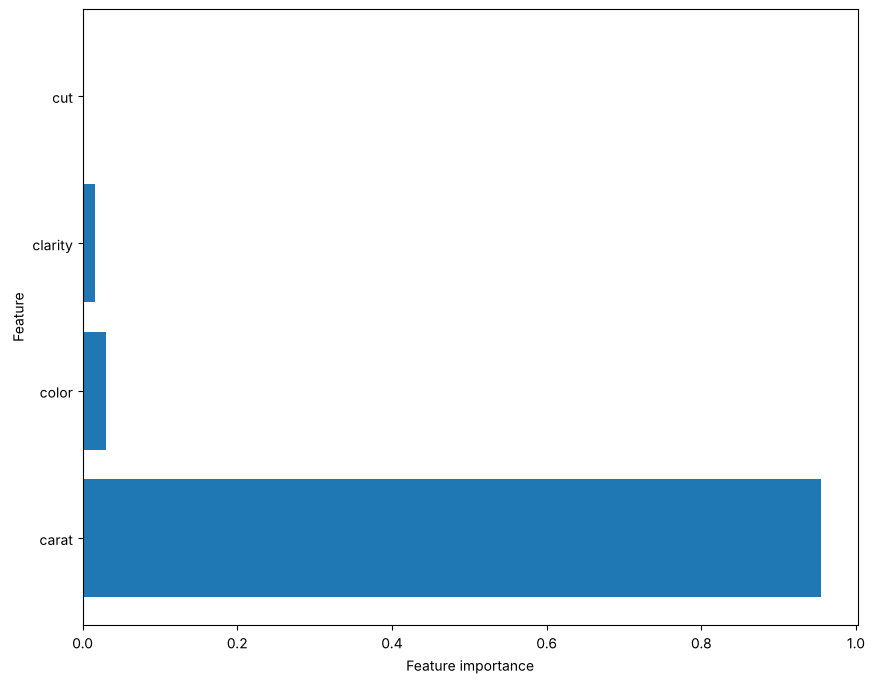

In [16]:
# base features: carat, color, clarity, cut
tree_base, x_train_base = run_tree(x_base, y_original,
                                   max_depth = 4, min_samples_leaf = 25,
                                   name = 'Base Features Tree')

plot_feature_importances(tree_base, train = x_train_base)

<strong>Analysis:</strong> the base-feature tree gives **exactly the same result** as the tree with all features: train 0.7592, test 0.7123, gap 0.047, and the same importances (carat 0.954, color 0.030, clarity 0.016, cut 0).

**New insight:** this answers the question from Part I. Unlike OLS, a regression tree **selects its own features**. The channel dummies were available in the full model, but the tree simply never chose them, so removing them changes nothing. We do not need to pre-select features by significance. We can give a tree all of the x-data and let feature importance show what matters. In this case, sales channel has no effect on the tree's predictions at this level of pruning.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<strong>b) Develop a regression tree using only <em>carat</em> and <em>color</em>.</strong><br>
Were the results the same as when using all of the x-features?

Carat and Color Tree
Training Score : 0.7491
Testing Score  : 0.7041
Train-Test Gap : 0.045


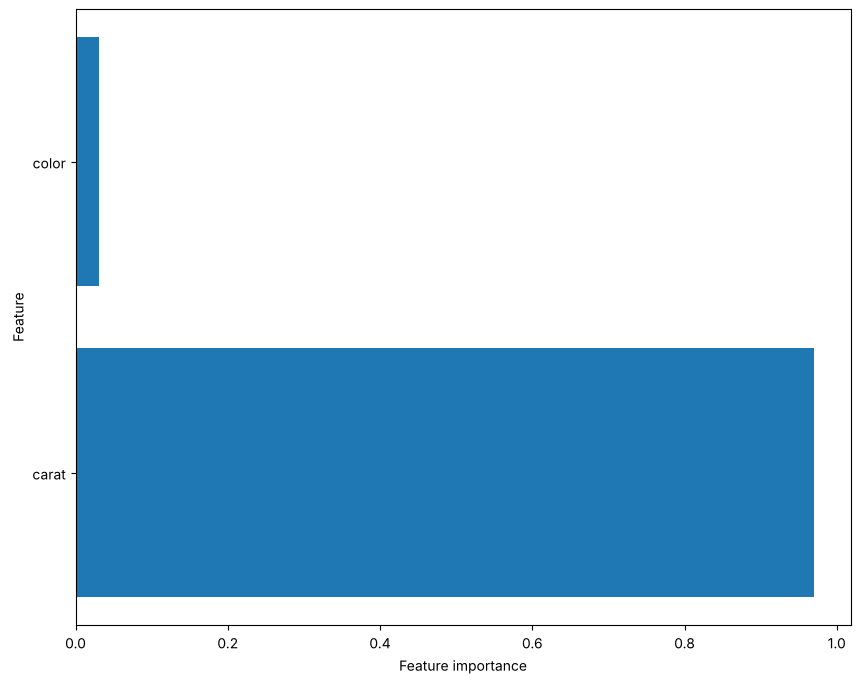

In [17]:
# only carat and color
x_carat_color = diamonds[ ['carat', 'color'] ]

tree_cc, x_train_cc = run_tree(x_carat_color, y_original,
                               max_depth = 4, min_samples_leaf = 25,
                               name = 'Carat and Color Tree')

plot_feature_importances(tree_cc, train = x_train_cc)

<strong>Analysis:</strong> **almost, but not exactly.** The test score falls only slightly, from 0.7123 to **0.7041** (about 0.01), and the gap stays below 0.05 (0.045). Carat's importance rises to 0.97 and color's stays at 0.03.

So, with only **two** features, the tree keeps about 99% of the full model's accuracy. Clarity added a little, and cut and the channels added nothing. For a quick price estimate, **carat and color are enough**. This is a much simpler story to tell a buyer.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<strong>c) Develop a regression tree using all features except <em>carat</em> and <em>color</em>.</strong><br>
How did the model perform? What new insights have you discovered?

Tree without Carat and Color
Training Score : 0.0662
Testing Score  : 0.016
Train-Test Gap : 0.0501


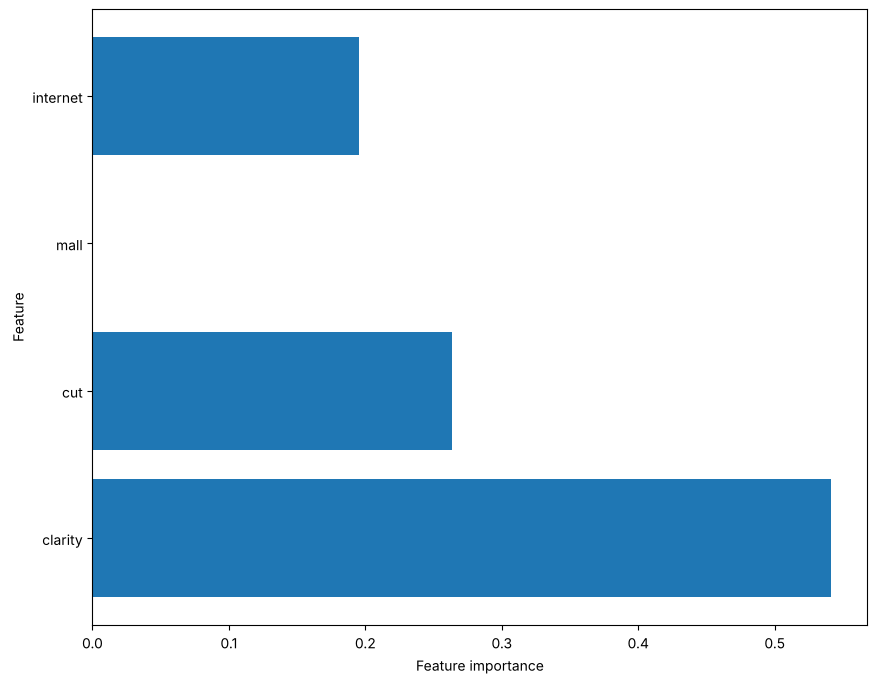

In [18]:
# all features except carat and color
x_no_cc = x_all.drop(labels = ['carat', 'color'], axis = 1)

tree_no_cc, x_train_no_cc = run_tree(x_no_cc, y_original,
                                     max_depth = 4, min_samples_leaf = 25,
                                     name = 'Tree without Carat and Color')

plot_feature_importances(tree_no_cc, train = x_train_no_cc)

In [19]:
# what does this tree split on?
print(export_text(tree_no_cc, feature_names = list(x_train_no_cc.columns), decimals = 2))

|--- cut <= 0.50
|   |--- internet <= 0.50
|   |   |--- value: [6039.22]
|   |--- internet >  0.50
|   |   |--- clarity <= 4.50
|   |   |   |--- value: [8327.12]
|   |   |--- clarity >  4.50
|   |   |   |--- clarity <= 5.50
|   |   |   |   |--- value: [6351.21]
|   |   |   |--- clarity >  5.50
|   |   |   |   |--- value: [7485.86]
|--- cut >  0.50
|   |--- clarity <= 5.50
|   |   |--- clarity <= 4.50
|   |   |   |--- value: [5639.76]
|   |   |--- clarity >  4.50
|   |   |   |--- value: [7465.84]
|   |--- clarity >  5.50
|   |   |--- value: [4857.66]



<strong>Analysis:</strong> the model **collapses**. Training R-square is only 0.066 and testing R-square is **0.016**, so it explains almost **none** of the price differences. It is barely better than predicting the average price for every diamond.

**New insights:**

* Without carat, the tree has to use clarity (importance 0.54), cut (0.26) and internet (0.20). But the leaf averages are all between about \$4,860 and \$8,330, with no clear pattern. For example, Ideal-cut diamonds with good clarity are predicted to be *cheaper* than some with worse clarity. These splits are mostly noise.
* Clarity, cut and channel **do** matter, but only **after** we know a diamond's size. They adjust the price of a diamond of a given weight; they cannot explain price on their own. This is the same pattern we saw in Script 03, where clarity and cut had weak correlations with price but were significant in the multi-feature OLS model.
* The gap (0.050) is right at the limit, even though both scores are tiny. A small gap does not mean a good model. We must always look at the scores themselves, too.

In [20]:
# summary of all trees in Part II and Part III
summary = []
for name, x_set in {'All features'         : x_all,
                    'Base features'        : x_base,
                    'Carat and color'      : x_carat_color,
                    'All but carat & color': x_no_cc}.items():

    x_tr, x_te, y_tr, y_te = train_test_split(x_set, y_original,
                                              test_size = 0.35, random_state = 702)
    tree = DecisionTreeRegressor(max_depth = 4, min_samples_leaf = 25,
                                 random_state = 702).fit(x_tr, y_tr)
    summary.append({'Feature Set'    : name,
                    'Training Score' : round(tree.score(x_tr, y_tr), 4),
                    'Testing Score'  : round(tree.score(x_te, y_te), 4),
                    'Train-Test Gap' : round(abs(tree.score(x_tr, y_tr) - tree.score(x_te, y_te)), 4)})

pd.DataFrame(summary)

,Feature Set,Training Score,Testing Score,Train-Test Gap
0,All features,0.7592,0.7123,0.0468
1,Base features,0.7592,0.7123,0.0468
2,Carat and color,0.7491,0.7041,0.0450
3,All but carat & color,0.0662,0.0160,0.0501


<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part IV: Case Study - Breaking Down the "Best" Diamond on a Budget</h2>
<strong>Goal: break down diamond prices using a regression tree.</strong> For this exercise the price limit is raised to \$7,250. A higher budget helps in two ways:

1. Terminal nodes predict the average price of their samples. Going over budget makes sure some terminal nodes have values near \$5,795.
2. There are more samples in the training and testing sets, which makes the model more stable.

<strong>a) Develop a regression tree where price ≤ 7250.</strong><br>
Then analyze the results. How would you explain the insights to someone wanting to buy a diamond engagement ring?

In [21]:
## x-side ##
x_budget = diamonds[ diamonds['price'] <= 7250 ].drop(labels = 'price', axis = 1)

## y-side ##
y_budget = diamonds[ diamonds['price'] <= 7250 ]['price']

In [22]:
# x-data
x_data = x_budget

# y_data
y_data = y_budget

# train-test split
x_train, x_test, y_train, y_test = train_test_split(x_data,
                                                    y_data,
                                                    test_size = 0.35,
                                                    random_state = 702)


# checking results
print(f"""
Data Shapes
-----------
x_train: {x_train.shape}
y_train: {y_train.shape}

x_test:  {x_test.shape}
y_test:  {y_test.shape}
""")


Data Shapes
-----------
x_train: (185, 6)
y_train: (185,)

x_test:  (101, 6)
y_test:  (101,)



286 diamonds cost \$7,250 or less: 185 for training and 101 for testing.

<strong>Choosing max_depth and min_samples_leaf.</strong> Before filling in the blanks, we test a few combinations. The goal is the best testing score with a gap below 0.05 and a tree that is still small enough to explain.

In [23]:
# testing combinations of pruning settings
tuning = []

for depth in [3, 4, 5, 6]:
    for leaf in [10, 15, 25]:
        tree = DecisionTreeRegressor(max_depth        = depth,
                                     min_samples_leaf = leaf,
                                     random_state     = 702).fit(x_train, y_train)

        train_score = tree.score(x_train, y_train)
        test_score  = tree.score(x_test,  y_test)

        tuning.append({'max_depth'        : depth,
                       'min_samples_leaf' : leaf,
                       'Terminal Nodes'   : tree.get_n_leaves(),
                       'Training Score'   : round(train_score, 4),
                       'Testing Score'    : round(test_score,  4),
                       'Train-Test Gap'   : round(abs(train_score - test_score), 4)})

pd.DataFrame(tuning).sort_values(by = 'Testing Score', ascending = False).head(n = 6)

,max_depth,min_samples_leaf,Terminal Nodes,Training Score,Testing Score,Train-Test Gap
9,6,10,12,0.8424,0.8311,0.0113
6,5,10,12,0.8424,0.8311,0.0113
3,4,10,11,0.8309,0.8310,0.0001
0,3,10,8,0.7895,0.8032,0.0137
11,6,25,6,0.7362,0.7694,0.0332
2,3,25,6,0.7362,0.7694,0.0332


**Depth 4 with 10 samples per leaf** is the best choice. Its testing score (0.8310) is practically equal to the best one (0.8311 for depth 5), it has a gap of almost 0, and it has fewer terminal nodes. That makes it the easiest tree to explain to a buyer.

In [24]:
# naming the model
model_name = 'Best Diamonds'

# INSTANTIATING a model object
model = DecisionTreeRegressor(max_depth        = 4,
                              min_samples_leaf = 10,
                              random_state     = 702)


# FITTING to the training data
model_fit = model.fit(x_train, y_train)


# PREDICTING on new data
model_pred = model.predict(x_test)


# SCORING the results
model_train_score = model.score(x_train, y_train) # using R-square
model_test_score  = model.score(x_test, y_test)   # using R-square
model_gap         = abs(model_train_score - model_test_score)


# displaying results
print('Training Score :', round(model_train_score, ndigits = 4))
print('Testing Score  :', round(model_test_score, ndigits = 4))
print('Train-Test Gap :', round(model_gap, ndigits = 4))

Training Score : 0.8309
Testing Score  : 0.831
Train-Test Gap : 0.0001


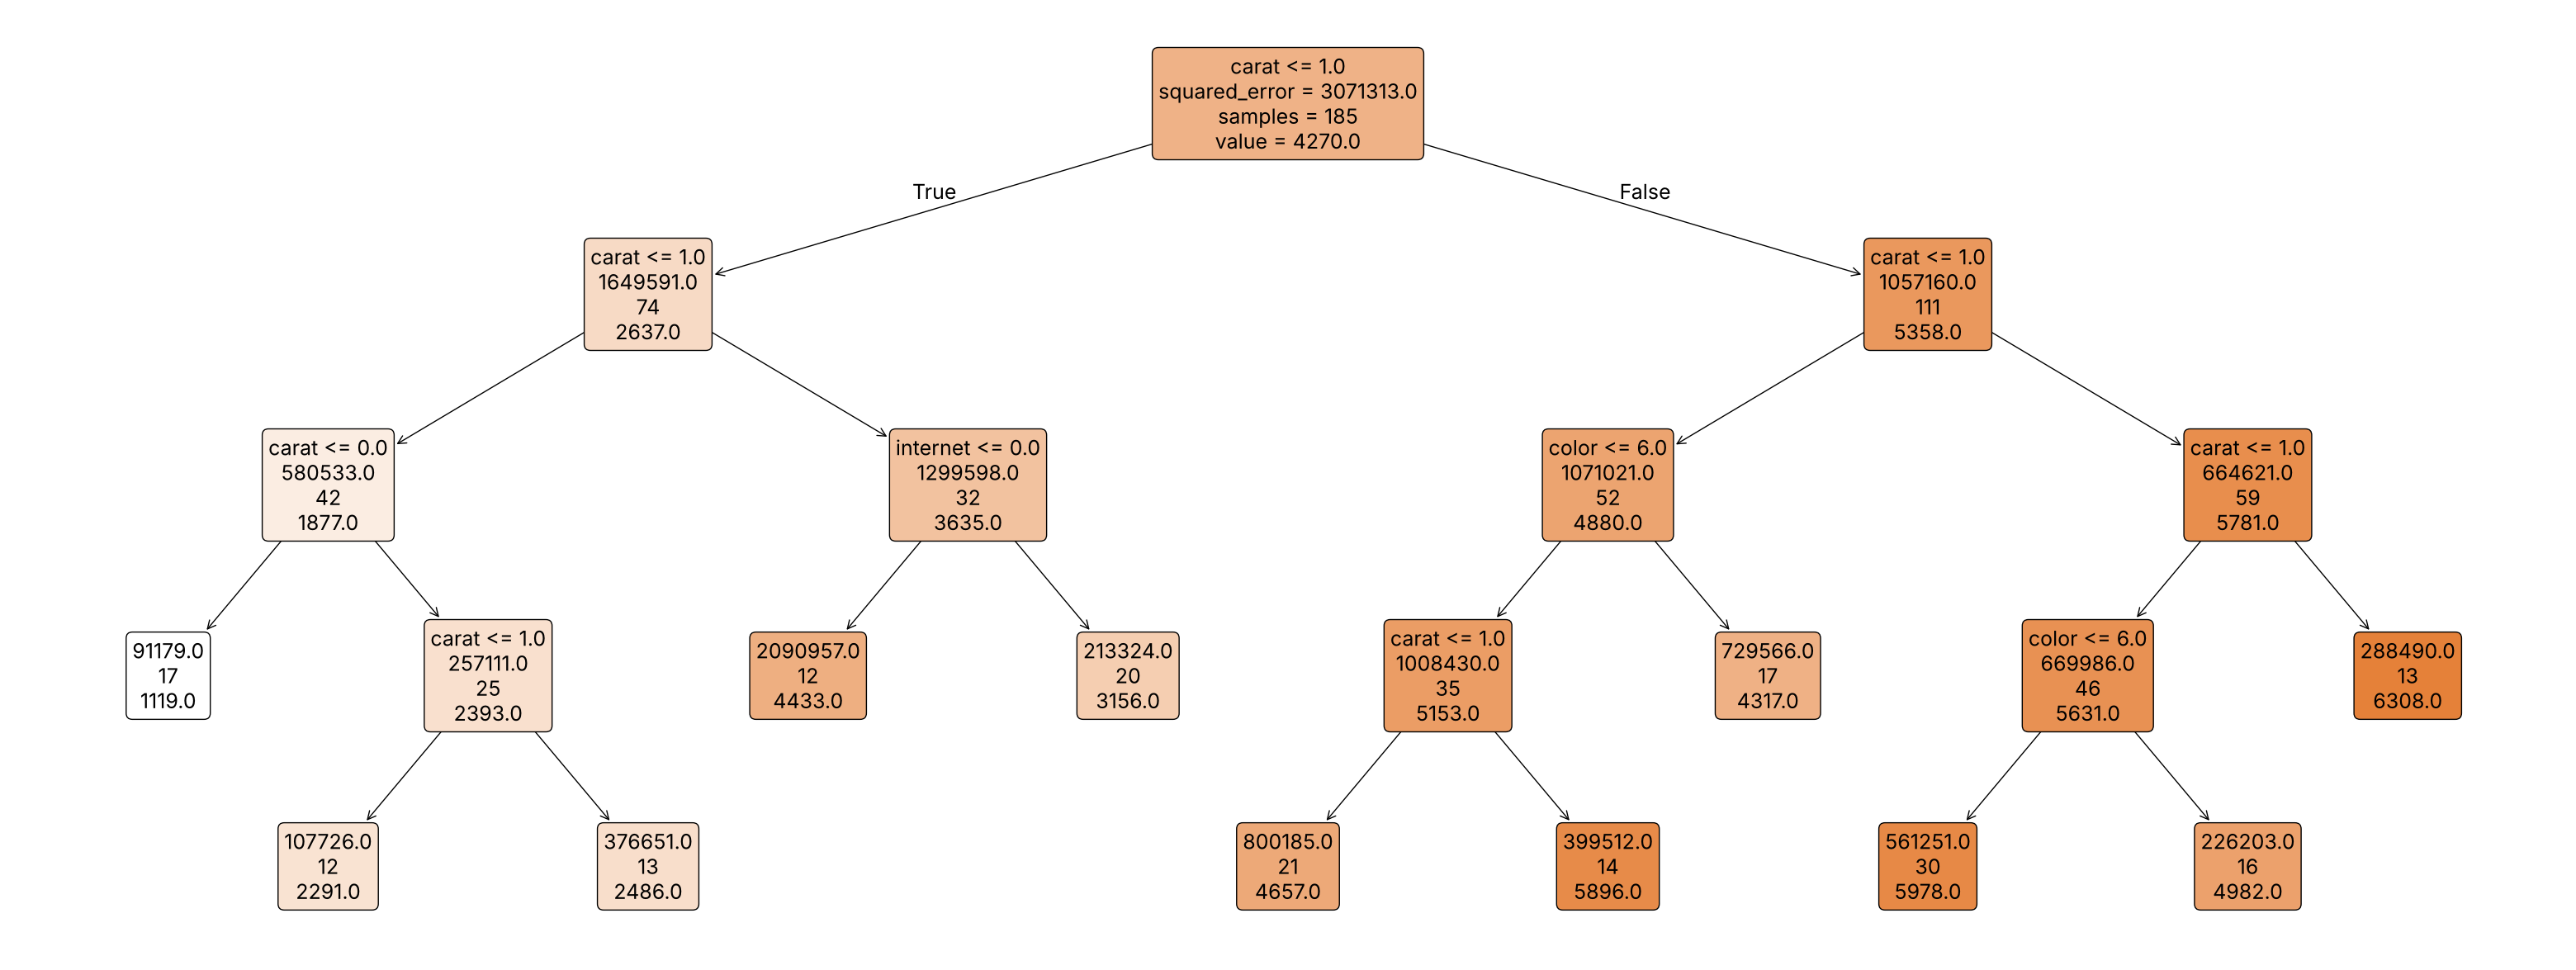

In [25]:
# setting figure size
plt.figure(figsize=(40, 15)) # adjusting for better visual


# developing a plotted tree
plot_tree(decision_tree = model,
          feature_names = list(x_train.columns),
          filled        = True,
          rounded       = True,
          fontsize      = 18,
          label         = 'root', # optional aesthetics
          precision     = 0)


# rendering the plot
plt.show()

In [26]:
# the same tree as text rules (easier to read than the plot)
print(export_text(model, feature_names = list(x_train.columns), decimals = 3))

|--- carat <= 0.760
|   |--- carat <= 0.645
|   |   |--- carat <= 0.445
|   |   |   |--- value: [1119.353]
|   |   |--- carat >  0.445
|   |   |   |--- carat <= 0.543
|   |   |   |   |--- value: [2290.917]
|   |   |   |--- carat >  0.543
|   |   |   |   |--- value: [2486.462]
|   |--- carat >  0.645
|   |   |--- internet <= 0.500
|   |   |   |--- value: [4432.833]
|   |   |--- internet >  0.500
|   |   |   |--- value: [3155.900]
|--- carat >  0.760
|   |--- carat <= 1.026
|   |   |--- color <= 6.500
|   |   |   |--- carat <= 1.005
|   |   |   |   |--- value: [4657.143]
|   |   |   |--- carat >  1.005
|   |   |   |   |--- value: [5896.286]
|   |   |--- color >  6.500
|   |   |   |--- value: [4316.882]
|   |--- carat >  1.026
|   |   |--- carat <= 1.205
|   |   |   |--- color <= 5.500
|   |   |   |   |--- value: [5978.033]
|   |   |   |--- color >  5.500
|   |   |   |   |--- value: [4981.500]
|   |   |--- carat >  1.205
|   |   |   |--- value: [6308.231]



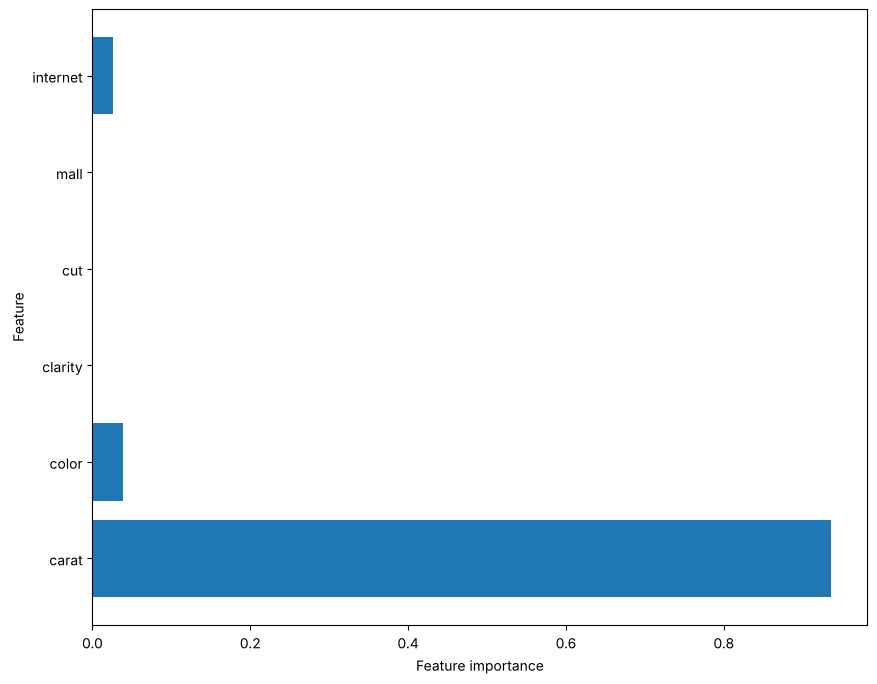

In [27]:
# plotting feature importance
plot_feature_importances(model,
                         train = x_train,
                         export = False)

In [28]:
# a buyer-friendly table of every terminal node
leaf_ids = model.apply(x_train)                     # which leaf each training diamond falls into

leaves = pd.DataFrame({'leaf'  : leaf_ids,
                       'carat' : x_train['carat'],
                       'color' : x_train['color'],
                       'price' : y_train})

leaf_table = leaves.groupby('leaf').agg(diamonds      = ('price', 'size'),
                                        min_carat     = ('carat', 'min'),
                                        max_carat     = ('carat', 'max'),
                                        best_color    = ('color', 'min'),
                                        worst_color   = ('color', 'max'),
                                        avg_price     = ('price', 'mean'))

leaf_table['within $5,795 budget'] = leaf_table['avg_price'] <= 5795
leaf_table.sort_values(by = 'min_carat').round(2)

,diamonds,min_carat,max_carat,best_color,worst_color,avg_price,"within $5,795 budget"
leaf,,,,,,,
3,17,0.35,0.42,1,6,1119.35,True
5,12,0.47,0.54,1,4,2290.92,True
6,13,0.55,0.63,2,5,2486.46,True
8,12,0.66,0.74,1,6,4432.83,True
9,20,0.70,0.75,1,6,3155.90,True
13,21,0.77,1.00,1,6,4657.14,True
15,17,0.97,1.02,7,9,4316.88,True
14,14,1.01,1.02,1,6,5896.29,False
18,30,1.03,1.20,1,5,5978.03,False


<h3>Results</h3>

* **Train 0.8309, test 0.8310, gap 0.0001.** The tree explains about 83% of price differences among diamonds of \$7,250 or less, and it predicts new diamonds just as well as the training ones.
* **Feature importance:** carat **0.935**, color **0.039**, internet **0.026**. Clarity, cut and mall are 0. This tree uses only three features.

<h3>What I would tell a friend buying an engagement ring (budget about \$5,795)</h3>

1. **Size sets the price.** About 94% of what this tree learns comes from carat weight. Decide first how big a stone you want, because that sets most of the cost.

2. **Avoid the "1 carat" premium.** Among stones from 0.77 to 1.02 carats with color 6 or better, diamonds **up to 1.00 carat average about \$4,660**, while those **just over 1 carat (1.01 to 1.02) average about \$5,900**. That is about **\$1,240 more for a few hundredths of a carat** that no one can see. A 0.90 to 1.00 carat stone gives almost the same look for much less.

3. **Your budget buys about 1 carat.** At \$5,795, the realistic choices are:
   * **0.77 to 1.00 carats with good color (6 or better):** about \$4,660. This is the best value and leaves money for the setting.
   * **1.03 to 1.20 carats with color 6 or worse:** about \$4,980. A bigger stone if you accept a slightly warmer color.
   * **1.03 to 1.20 carats with color 5 or better:** about \$5,980. This is just over the budget.
   * **Above 1.20 carats:** about \$6,310 on average, which is over the budget.

4. **Color matters only once the stone is big.** The tree uses color only for stones above 0.76 carats. For bigger stones, giving up a little color (6 or 7 instead of 5) saves about \$1,000.

5. **Clarity and cut barely move the price in this range.** The tree never uses them. In this price range, paying extra for a better clarity or cut grade buys little extra value. Choose a clarity where no flaws can be seen by eye (about 5, VS2) and spend the rest on size or color.

6. **For smaller stones, shop online.** For diamonds from 0.65 to 0.76 carats, internet stores average about **\$3,160**, compared with about **\$4,430** in malls and independent jewelers. That is a saving of about **\$1,280**.

<em>Note:</em> these results come from about 10 to 30 diamonds per leaf, so the dollar amounts are averages and estimates, not exact prices. The direction of each finding is more reliable than the exact numbers.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<hr style="height:.9px;border:none;color:#333;background-color:#333;" />

~~~
      ___  ___  __
|__/ |__  |__  |__)
|  \ |___ |___ |

 __   __   __               __    /
/ _` |__) /  \ |  | | |\ | / _`  /
\__> |  \ \__/ |/\| | | \| \__> .
~~~
<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<hr style="height:.9px;border:none;color:#333;background-color:#333;" />